# HDD 05B — Representation ablation: levels and daily changes
Run this independent notebook in **VS Code** after Notebooks 04 and 05. It uses existing saved data, not variables from their kernels.

**Question:** do explicit daily changes produce more reproducible behaviour clusters than the original level-only representation?

Compare three representations under the same training-window sample, HDBSCAN grid and drive-resampling tests:
1. **existing_level_encoder** — saved Notebook 04 embeddings.
2. **level_change_encoder** — a new masked Transformer receiving levels and usable adjacent-day changes, trained to reconstruct hidden levels.
3. **change_summary_baseline** — simple numerical summaries of daily changes, without a neural network.

This is an exploratory pipeline comparison using the already examined development data. It is not a causal proof that any improvement comes only from daily changes: the new model has a larger input layer, a separately trained checkpoint, and adds an input-availability channel. A strictly matched new level-only control and five neural seeds are later experiments.

Existing Notebooks 04/05 remain first-experiment evidence. This notebook writes new output folders. No real failure labels or June files are opened, and no cluster is labelled healthy or failing. It can finish with no supported representation; never force the readiness flag.

Your earlier results motivated this experiment: unstable HDBSCAN partitions dominated by persistent drive characteristics, and strong synthetic spike sensitivity only when scoring final-day reconstruction errors. Those findings are not final failure-detection performance.


## 1. Dependencies and runtime


In [1]:
%pip -q install "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "pyarrow>=16" "hdbscan>=0.8.40,<0.9" torch joblib matplotlib tqdm


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Locate and verify the original saved data
The default path matches your uploaded Notebook 03. Correct COMPONENT_ROOT if you moved the repository. OLD_SSL_ID must match Notebook 04. Do not copy or regenerate previous completion files manually.

Hash the original checkpoint without loading it. Match metadata rows before comparing representations. This notebook does not depend on extra diagnostic cells you added to Notebooks 04/05.


In [2]:
from pathlib import Path
import json, hashlib, copy, random, os, time, warnings, platform
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib, sklearn, hdbscan
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from hdbscan.prediction import approximate_predict
from hdbscan.validity import validity_index
from tqdm.auto import tqdm

COMPONENT_ROOT=Path(r'D:/SLIIT/Y4S1/RP/Research/J26-DS-342-/01_component_1_behavioral_drift_genai')
RUN_ID='single_model_q1q2_2021_v1'
OLD_SSL_ID='masked_transformer_v1_seed42'
ABLATION_ID='representation_ablation_v1_seed42'
SEED=42

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as handle:
        for chunk in iter(lambda:handle.read(1024*1024),b''):h.update(chunk)
    return h.hexdigest()

old_complete_path=COMPONENT_ROOT/'results'/RUN_ID/OLD_SSL_ID/'encoder_complete.json'
if not old_complete_path.is_file():
    raise FileNotFoundError(f'Notebook 04 completion file missing: {old_complete_path.resolve()}')
old_record=json.loads(old_complete_path.read_text())
assert old_record['run_id']==RUN_ID and old_record['ssl_id']==OLD_SSL_ID
assert old_record['failure_labels_used'] is False and old_record['sealed_test_opened'] is False
for relative,digest in old_record['representation_files'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed old encoder output: {relative}'
old_checkpoint=COMPONENT_ROOT/'models/trained'/RUN_ID/OLD_SSL_ID/'best_encoder.pt'
assert sha256(old_checkpoint)==old_record['checkpoint_sha256']
complete_path=COMPONENT_ROOT/'experiments'/RUN_ID/'dataset_complete.json'
assert sha256(complete_path)==old_record['settings']['dataset_complete_sha256']
complete=json.loads(complete_path.read_text())
assert complete['status']=='passed'
for relative,digest in complete['working_hashes'].items():
    assert sha256(COMPONENT_ROOT/relative)==digest, f'Changed original dataset file: {relative}'
config_path=COMPONENT_ROOT/'config'/f'{RUN_ID}.json'
assert sha256(config_path)==complete['config_sha256']
cfg=json.loads(config_path.read_text());FEATURES=cfg['raw_features'];T=cfg['window_days'];F=len(FEATURES)
assert F==5 and T==30, 'This first ablation was declared for 30-day, five-attribute windows.'
prep_path=COMPONENT_ROOT/'models/trained'/f'{RUN_ID}_daily_preprocessing.json'
prep=json.loads(prep_path.read_text());assert prep['features']==FEATURES
assert sha256(prep_path)==old_record['settings']['preprocessing_sha256']
FEATURE_ROOT=COMPONENT_ROOT/'data/features'/RUN_ID
OUT=COMPONENT_ROOT/'results'/RUN_ID/ABLATION_ID
MODELS=COMPONENT_ROOT/'models/trained'/RUN_ID/ABLATION_ID
EXPORT=FEATURE_ROOT/ABLATION_ID
for folder in [OUT,MODELS,EXPORT]:folder.mkdir(parents=True,exist_ok=True)
LEVEL,RAW,META,OLD_EMBED={},{},{},{}
for split in ['train','calibration','development']:
    folder=FEATURE_ROOT/split
    with np.load(folder/'windows_raw.npz') as a:RAW[split]=a['X'].astype(np.float32)
    with np.load(folder/'windows_scaled.npz') as a:
        LEVEL[split]=a['X'].astype(np.float32)
        assert a['observed_mask'].all(), 'Partially observed windows need a separately declared mask policy.'
    META[split]=pd.read_parquet(folder/'metadata.parquet').reset_index(drop=True)
    old_folder=FEATURE_ROOT/OLD_SSL_ID/split
    pd.testing.assert_frame_equal(META[split],pd.read_parquet(old_folder/'metadata.parquet').reset_index(drop=True))
    with np.load(old_folder/'representations.npz') as a:OLD_EMBED[split]=a['embeddings'].astype(np.float64)
    assert RAW[split].shape==LEVEL[split].shape==(len(META[split]),T,F)
    assert len(OLD_EMBED[split])==len(META[split])
    assert np.isfinite(RAW[split]).all() and (RAW[split]>=0).all() and np.isfinite(LEVEL[split]).all()
    assert not META[split].duplicated(['serial_number','end_date']).any()
    print(split,RAW[split].shape)
for a in META:
    for b in META:
        if a!=b:assert set(META[a]['serial_number']).isdisjoint(META[b]['serial_number'])
print('Original working data verified. June and real outcomes remain closed.')


c:\Users\IMAKA\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train (42578, 30, 5)
calibration (4410, 30, 5)
development (4642, 30, 5)
Original working data verified. June and real outcomes remain closed.


## 3. Declare the protocol before running experiments
The internal stopping serials, architecture width, masking rate, span length and level-reconstruction target follow Notebook 04. Only usable daily-change information is added as input. Early stopping is an internal optimisation check: existing level preprocessing was fitted on the whole training cohort.

All eligible HDBSCAN candidates receive the same three drive-resampling tests before diagnostic selection. Positive sampled DBCV plus stable assignments are treated as support for a **partition**, not proof of meaningful temporal regimes. We separately report whether labels vary within drives more than a shuffled control.

Use a new ABLATION_ID if you change settings. Existing best checkpoints are reused; interrupted training is not resumed exactly from its optimizer state.


In [3]:
SETTINGS={
    'seed':SEED,'width':32,'heads':4,'layers':2,'feedforward':64,'dropout':.1,
    'point_mask_probability':.15,'span_days':3,'batch_size':128,'max_epochs':50,'patience':8,
    'learning_rate':1e-3,'weight_decay':1e-5,'stopping_max_windows':2048,
    'change_definition':'raw adjacent-day difference; signed log1p for count/usage features; temperature difference unchanged',
    'change_visibility':'available only if both source levels visible; first within-window change unavailable',
    'fit_spacing_days':10,'fit_max_per_drive':8,'fit_max_total':6000,'pca_cap':8,'dbcv_sample_max':1500,
    'min_cluster_sizes':[30,60,120],'min_samples_values':[5,15],
    'minimum_assigned_fraction':.5,'minimum_unique_drives_per_cluster':5,
    'stability_seeds':[43,44,45],'stability_drive_fraction':.8,'stability_anchor_max':5000,
    'minimum_joint_fraction':.5,'ari_target':.70,'shuffle_repeats':20,
    'temporal_diagnostic_min_switching_drives':5,'temporal_diagnostic_min_lift':.01,
    'temporal_diagnostic_note':'new explicit exploratory flag, not a final validated acceptance criterion',
    'old_encoder_complete_sha256':sha256(old_complete_path),'dataset_complete_sha256':sha256(complete_path),
    'daily_preprocessing_sha256':sha256(prep_path),
}
settings_path=MODELS/'settings.json'
if settings_path.exists() and json.loads(settings_path.read_text())!=SETTINGS:
    raise ValueError('Settings changed. Use a new ABLATION_ID instead of mixing experiments.')
settings_path.write_text(json.dumps(SETTINGS,indent=2))
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic=True;torch.backends.cudnn.benchmark=False
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type=='cpu':torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
print('Device:',DEVICE)
print('Previous experiments are loaded for comparison; new outputs use:',OUT)


Device: cpu
Previous experiments are loaded for comparison; new outputs use: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\representation_ablation_v1_seed42


## 4. Fit daily-change preprocessing on unique training transitions
Use the original training daily table, sorted by serial/date, and only consecutive, fully usable pairs on or before the training cutoff. Never take a difference across drives or a calendar gap. Negative differences are retained as observations: counter resets and decreases need investigation, not automatic deletion.

Raw SMART 9 units remain unverified for this model, so label its differences as raw changes rather than literal operating hours. Signed `log1p` limits the influence of large counter changes; temperature changes are not logged. A zero-IQR feature uses scale 1. A constant counter is retained so rare changes are not discarded.

The new input scaler is fitted on unique training transitions. The old level preprocessing remains frozen. Natural first-day change is unavailable inside each window, represented by a dedicated availability channel.


In [4]:
COUNT_INDICES=[FEATURES.index(f) for f in prep['log_features']]

def signed_changes(differences):
    values=np.array(differences,dtype=np.float64,copy=True)
    for j in COUNT_INDICES:values[...,j]=np.sign(values[...,j])*np.log1p(np.abs(values[...,j]))
    return values

def scale_levels(raw):
    values=raw.astype(np.float64,copy=True)
    for j in COUNT_INDICES:values[...,j]=np.log1p(values[...,j])
    return ((values-np.array(prep['center']))/np.array(prep['scale'])).astype(np.float32)

train_daily_path=COMPONENT_ROOT/'data/processed'/RUN_ID/'train'/'daily.parquet'
if not train_daily_path.is_file():raise FileNotFoundError(f'Missing Notebook 02 training daily table: {train_daily_path}')
daily=pd.read_parquet(train_daily_path)
assert not daily.duplicated(['serial_number','date']).any()
assert set(daily['serial_number']).issubset(set(META['train']['serial_number']))
train_end=META['train']['end_date'].max()
daily=daily.loc[daily['date'].le(train_end)].sort_values(['serial_number','date']).copy()
# Confirm that the daily table agrees with every accepted training window.
lookup=daily.set_index(['serial_number','date'])[FEATURES]
for serial,indices in META['train'].groupby('serial_number').groups.items():
    dates=META['train'].loc[indices,'start_date'].to_numpy()[:,None]+np.arange(T)[None,:]*np.timedelta64(1,'D')
    keys=pd.MultiIndex.from_arrays([np.repeat(serial,dates.size),dates.ravel()])
    actual=lookup.reindex(keys).to_numpy(dtype=np.float32).reshape(len(indices),T,F)
    np.testing.assert_allclose(actual,RAW['train'][np.asarray(indices)],rtol=0,atol=0)
previous=daily.groupby('serial_number')[FEATURES].shift(1)
consecutive=daily.groupby('serial_number')['date'].diff().dt.days.eq(1)
current=daily[FEATURES].to_numpy(dtype=float);prior=previous.to_numpy(dtype=float)
usable=consecutive.to_numpy() & np.isfinite(current).all(1) & np.isfinite(prior).all(1) & (current>=0).all(1) & (prior>=0).all(1)
assert usable.any()
raw_transitions=current[usable]-prior[usable]
transitions=signed_changes(raw_transitions)
delta_center=np.median(transitions,axis=0)
iqr=np.quantile(transitions,.75,axis=0)-np.quantile(transitions,.25,axis=0)
delta_scale=np.where(iqr>1e-12,iqr,1.)
delta_prep={'features':FEATURES,'center':delta_center.tolist(),'scale':delta_scale.tolist(),
    'original_iqr':iqr.tolist(),'unique_training_transitions':len(transitions),
    'training_daily_sha256':sha256(train_daily_path),'train_end':str(train_end),'signed_log_indices':COUNT_INDICES}
delta_path=MODELS/'change_preprocessing.json'
if delta_path.exists() and json.loads(delta_path.read_text())!=delta_prep:
    raise ValueError('Training daily inputs/change preprocessing changed. Use a new ABLATION_ID.')
delta_path.write_text(json.dumps(delta_prep,indent=2))
change_audit=pd.DataFrame({'attribute':FEATURES,'negative_changes':(raw_transitions<0).sum(0),
    'zero_changes':(raw_transitions==0).sum(0),'transformed_iqr':iqr})
change_audit.to_csv(OUT/'training_change_audit.csv',index=False);display(change_audit)

def change_channels(raw):
    changes=np.zeros_like(raw,dtype=np.float32)
    changes[:,1:,:]=((signed_changes(np.diff(raw.astype(np.float64),axis=1))-delta_center)/delta_scale).astype(np.float32)
    return changes

CHANGE={split:change_channels(values) for split,values in RAW.items()}
for split in LEVEL:
    np.testing.assert_allclose(scale_levels(RAW[split]),LEVEL[split],rtol=1e-5,atol=1e-6)
    assert np.isfinite(CHANGE[split]).all()
print('Daily-change channels prepared using training-only statistics.')
del daily,previous,current,prior,lookup,raw_transitions,transitions


,attribute,negative_changes,zero_changes,transformed_iqr
0,smart_5_raw,0,62270,0.000000
1,smart_9_raw,0,10,0.663294
2,smart_194_raw,15694,30503,2.000000
3,smart_197_raw,1,62276,0.000000
4,smart_198_raw,1,62276,0.000000


Daily-change channels prepared using training-only statistics.


## 5. Mask the level and every derived input that depends on it
For change at day t, both level t and level t−1 must remain visible. If a level is hidden, changes at that day **and the following day** are unavailable. This prevents algebraic target leakage from differences.

The network receives five groups of channels per day: corrupted levels, usable changes, original observation indicators, artificial hidden indicators, and change-availability indicators. All current source windows are fully observed; extend natural-missingness handling only in a new experiment.

Loss reconstructs hidden levels only. We do not simultaneously reconstruct deltas, because that would change the target objective as well as the inputs. Five fixed masking passes hide each original level exactly once at inference. Embeddings average pooled hidden states across those passes.


In [5]:
def masks_for_scoring(t,f):
    grid=(torch.arange(t)[:,None]+torch.arange(f)[None,:])%f
    partitions=[grid.eq(k) for k in range(f)]
    assert torch.stack(partitions).sum(0).eq(1).all()
    return partitions
PARTITIONS=masks_for_scoring(T,F)

def random_hide(batch,generator):
    b,t,f=batch.shape
    hide=torch.rand((b,t,f),generator=generator)<SETTINGS['point_mask_probability']
    span=min(t,SETTINGS['span_days'])
    starts=torch.randint(0,t-span+1,(b,),generator=generator)
    channels=torch.randint(0,f,(b,),generator=generator)
    for i in range(b):hide[i,starts[i]:starts[i]+span,channels[i]]=True
    return hide

class LevelChangeEncoder(nn.Module):
    def __init__(self):
        super().__init__();width=SETTINGS['width']
        self.input_projection=nn.Linear(5*F,width)
        self.position=nn.Parameter(torch.empty(1,T,width));nn.init.normal_(self.position,std=.02)
        block=nn.TransformerEncoderLayer(width,SETTINGS['heads'],SETTINGS['feedforward'],SETTINGS['dropout'],
            activation='gelu',batch_first=True,norm_first=False)
        self.encoder=nn.TransformerEncoder(block,SETTINGS['layers'],enable_nested_tensor=False)
        for layer in self.encoder.layers:
            for parameter in layer.parameters():
                if parameter.dim()>1:nn.init.xavier_uniform_(parameter)
        self.decoder=nn.Linear(width,F)
    def forward(self,levels,changes,hide):
        visible=~hide
        delta_available=torch.zeros_like(visible)
        delta_available[:,1:]=visible[:,1:] & visible[:,:-1]
        channels=torch.cat([levels.masked_fill(hide,0.),changes.masked_fill(~delta_available,0.),
            torch.ones_like(levels),hide.float(),delta_available.float()],dim=-1)
        hidden=self.encoder(self.input_projection(channels)+self.position[:,:levels.shape[1]])
        return self.decoder(hidden),hidden.mean(1)

model=LevelChangeEncoder().to(DEVICE)
model.eval()
with torch.no_grad():
    demo=RAW['train'][:2].copy();hide=PARTITIONS[0].unsqueeze(0).expand(len(demo),-1,-1).to(DEVICE)
    changed=demo.copy();changed[hide.cpu().numpy()]+=100
    def tensors(raw):return (torch.tensor(scale_levels(raw),device=DEVICE),torch.tensor(change_channels(raw),device=DEVICE))
    a,_=model(*tensors(demo),hide);b,_=model(*tensors(changed),hide)
    assert torch.allclose(a,b,rtol=1e-5,atol=1e-6), 'Hidden target leaked through a level or difference.'
print('Leakage check passed: perturbing hidden levels and recalculating their changes leaves predictions unchanged.')
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))


Leakage check passed: perturbing hidden levels and recalculating their changes leaves predictions unchanged.
Trainable parameters: 19045


## 6. Train the new representation with an internal stopping cohort
Use the same serial split rule as Notebook 04, then a fixed subset of at most 2,048 stopping windows. Training/random-span and stopping/fixed-mask losses use different corruption patterns; compare their trends, not a claim that one should always be lower.

The best checkpoint is saved atomically whenever stopping loss improves. On rerun, reload it and skip training. An interrupted run retains a usable best checkpoint but is explicitly marked incomplete. Exact optimizer resumption is not implemented.


In [6]:
@torch.no_grad()
def infer_new(levels,changes,progress=False):
    model.eval();embeddings=[];per_feature=[];last_day=[]
    loader=DataLoader(TensorDataset(torch.from_numpy(np.asarray(levels,dtype=np.float32)),torch.from_numpy(np.asarray(changes,dtype=np.float32))),batch_size=SETTINGS['batch_size'],shuffle=False,num_workers=0)
    for x,d in (tqdm(loader,desc='New encoder inference',leave=False) if progress else loader):
        x=x.to(DEVICE);d=d.to(DEVICE);errors=torch.zeros_like(x);latent=None
        for partition in PARTITIONS:
            hide=partition.to(DEVICE).unsqueeze(0).expand_as(x)
            prediction,z=model(x,d,hide)
            errors+=torch.where(hide,(prediction-x).square(),torch.zeros_like(x))
            latent=z if latent is None else latent+z
        assert torch.isfinite(errors).all()
        embeddings.append((latent/F).cpu().numpy());per_feature.append(errors.mean(1).cpu().numpy());last_day.append(errors[:,-1,:].cpu().numpy())
    return {'embeddings':np.concatenate(embeddings),'feature_errors':np.concatenate(per_feature),'last_day_errors':np.concatenate(last_day)}

serials=np.array(sorted(META['train']['serial_number'].unique()));np.random.default_rng(SEED+2).shuffle(serials)
stop_ids=set(serials[:max(1,int(.15*len(serials)))])
stop_selection=META['train']['serial_number'].isin(stop_ids).to_numpy();fit_selection=~stop_selection
assert stop_selection.any() and fit_selection.any()
stop_indices=np.flatnonzero(stop_selection)
if len(stop_indices)>SETTINGS['stopping_max_windows']:
    stop_indices=stop_indices[np.random.default_rng(SEED+4).choice(len(stop_indices),SETTINGS['stopping_max_windows'],replace=False)]
checkpoint_path=MODELS/'level_change_encoder.pt';training_record_path=MODELS/'training_record.json'
model_input_hash=hashlib.sha256((sha256(settings_path)+sha256(delta_path)).encode()).hexdigest()
if checkpoint_path.exists():
    saved=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True)
    assert saved['model_input_hash']==model_input_hash
    model.load_state_dict(saved['state_dict']);best_epoch=saved['best_epoch'];best_loss=saved['best_loss']
    training_record=json.loads(training_record_path.read_text()) if training_record_path.exists() else {'completed':False,'history':saved['history'],'reason':'interrupted after best checkpoint'}
    history=training_record['history']
    print('Loaded previous best new-encoder checkpoint:',best_epoch,best_loss)
else:
    loader=DataLoader(TensorDataset(torch.from_numpy(LEVEL['train'][fit_selection]),torch.from_numpy(CHANGE['train'][fit_selection])),batch_size=SETTINGS['batch_size'],shuffle=True,num_workers=0,generator=torch.Generator().manual_seed(SEED))
    generator=torch.Generator().manual_seed(SEED+10)
    optimizer=torch.optim.AdamW(model.parameters(),lr=SETTINGS['learning_rate'],weight_decay=SETTINGS['weight_decay'])
    history=[];best_loss=float('inf');best_epoch=0;stale=0;started=time.perf_counter()
    for epoch in range(1,SETTINGS['max_epochs']+1):
        model.train();total=0.;count=0
        for cpu_x,cpu_d in tqdm(loader,desc=f'Epoch {epoch}',leave=False):
            hide=random_hide(cpu_x,generator).to(DEVICE);x=cpu_x.to(DEVICE);d=cpu_d.to(DEVICE)
            predicted,_=model(x,d,hide);errors=(predicted-x).square();loss=errors[hide].mean()
            if not torch.isfinite(loss):raise ValueError('Nonfinite loss: inspect scales and source values.')
            optimizer.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step()
            total+=errors[hide].detach().sum().item();count+=int(hide.sum().item())
        result=infer_new(LEVEL['train'][stop_indices],CHANGE['train'][stop_indices])
        stop_loss=float(result['feature_errors'].mean())
        history.append({'epoch':epoch,'masked_training_mse':total/count,'stopping_mse':stop_loss})
        print(f'Epoch {epoch:02d} | train {total/count:.6f} | stopping {stop_loss:.6f}')
        if stop_loss<best_loss-1e-6:
            best_epoch=epoch;best_loss=stop_loss;stale=0
            payload={'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},'best_epoch':best_epoch,'best_loss':best_loss,'model_input_hash':model_input_hash,'history':copy.deepcopy(history)}
            temporary=checkpoint_path.with_suffix('.pt.tmp');torch.save(payload,temporary);temporary.replace(checkpoint_path)
        else:stale+=1
        if stale>=SETTINGS['patience']:break
    training_record={'completed':True,'history':history,'epochs_completed':len(history),'hit_epoch_limit':len(history)==SETTINGS['max_epochs'],'seconds':time.perf_counter()-started}
    training_record_path.write_text(json.dumps(training_record,indent=2))
    saved=torch.load(checkpoint_path,map_location=DEVICE,weights_only=True);model.load_state_dict(saved['state_dict'])
pd.DataFrame(history).to_csv(OUT/'new_encoder_training_history.csv',index=False)
(MODELS/'internal_stopping_serials.json').write_text(json.dumps(sorted(str(x) for x in stop_ids),indent=2))
print('Best epoch:',best_epoch,'| masked stopping loss:',best_loss)
print('Complete training run:',training_record['completed'])


Epoch 01 | train 0.068803 | stopping 0.009810


Epoch 02 | train 0.022696 | stopping 0.009935


Epoch 03 | train 0.016087 | stopping 0.009285


Epoch 04 | train 0.013519 | stopping 0.008779


Epoch 05 | train 0.012344 | stopping 0.008509


...

Epoch 46 | train 0.005921 | stopping 0.004558


Epoch 47 | train 0.005969 | stopping 0.004664


Epoch 48 | train 0.005887 | stopping 0.004465


Epoch 49 | train 0.005873 | stopping 0.004560


Epoch 50 | train 0.006083 | stopping 0.004451
Best epoch: 44 | masked stopping loss: 0.004439608193933964
Complete training run: True


## 7. Export the three representations
The simple baseline uses mean, standard deviation, 95th absolute-change percentile, final change and summed change over the 29 valid within-window transitions. It deliberately omits absolute levels. Summed signed-log changes are transformed-change summaries, not physical net changes.

The new encoder exports per-feature 30-day and final-day reconstruction errors for future scoring experiments. This notebook focuses on regime representations; it does not select anomaly thresholds or claim better failure detection.


In [7]:
new_results={};REPRESENTATIONS={'existing_level_encoder':OLD_EMBED,'level_change_encoder':{},'change_summary_baseline':{}}
for split in ['train','calibration','development']:
    new_results[split]=infer_new(LEVEL[split],CHANGE[split],progress=True)
    REPRESENTATIONS['level_change_encoder'][split]=new_results[split]['embeddings'].astype(np.float64)
    d=CHANGE[split][:,1:,:].astype(np.float64)
    REPRESENTATIONS['change_summary_baseline'][split]=np.concatenate([d.mean(1),d.std(1),np.quantile(np.abs(d),.95,axis=1),d[:,-1,:],d.sum(1)],axis=1)
    folder=EXPORT/'new_encoder'/split;folder.mkdir(parents=True,exist_ok=True)
    np.savez_compressed(folder/'representations.npz',**new_results[split])
    META[split].to_parquet(folder/'metadata.parquet',index=False)
for name,parts in REPRESENTATIONS.items():
    for split,values in parts.items():
        assert len(values)==len(META[split]) and np.isfinite(values).all()
    print(name,'training shape:',parts['train'].shape)
# Check repeatability for a small batch; dropout must be off during inference.
a=infer_new(LEVEL['development'][:4],CHANGE['development'][:4])
b=infer_new(LEVEL['development'][:4],CHANGE['development'][:4])
np.testing.assert_allclose(a['embeddings'],b['embeddings'],rtol=1e-5,atol=1e-6)


existing_level_encoder training shape: (42578, 32)
level_change_encoder training shape: (42578, 32)
change_summary_baseline training shape: (42578, 25)


## 8. Use the same training sample and anchor indices for every representation
Fit each representation's scaler/PCA on the same temporally thinned, drive-balanced training sample. Use a PCA cap of 8 as before; report retained variance separately for each method. Its exact retained information differs across methods, so no-PCA and alternate-dimensionality comparisons remain later ablations.

Clustering never reads April/May when selecting parameters. A fixed set of full-training anchors supports agreement comparisons, and a fixed subset of fitting points supports sampled DBCV. This preserves comparisons across candidates without allocating full 42,000-window pairwise matrices.


In [8]:
def fitting_indices(meta):
    groups=[]
    for _,part in meta.groupby('serial_number',sort=True):
        chosen=[];previous=None
        for index,row in part.sort_values('end_date').iterrows():
            endpoint=pd.Timestamp(row['end_date'])
            if previous is None or (endpoint-previous).days>=SETTINGS['fit_spacing_days']:
                chosen.append(int(index));previous=endpoint
            if len(chosen)>=SETTINGS['fit_max_per_drive']:break
        groups.append(chosen)
    np.random.default_rng(SEED).shuffle(groups);indices=[]
    for rank in range(SETTINGS['fit_max_per_drive']):
        for group in groups:
            if rank<len(group):indices.append(group[rank])
            if len(indices)>=SETTINGS['fit_max_total']:return np.array(sorted(indices))
    return np.array(sorted(indices))

fit_indices=fitting_indices(META['train'])
if len(fit_indices)<150:raise ValueError('Too few fitting windows for the declared grid. Inspect coverage; use a new protocol if needed.')
fit_meta=META['train'].iloc[fit_indices].reset_index(drop=True)
fit_meta.assign(original_window_index=fit_indices).to_csv(OUT/'shared_fitting_windows.csv',index=False)
anchor_indices=np.sort(np.random.default_rng(SEED+50).choice(len(META['train']),min(SETTINGS['stability_anchor_max'],len(META['train'])),replace=False))
metric_indices=np.sort(np.random.default_rng(SEED).choice(len(fit_indices),min(SETTINGS['dbcv_sample_max'],len(fit_indices)),replace=False))
np.savez_compressed(MODELS/'shared_indices.npz',fit_indices=fit_indices,anchor_indices=anchor_indices,metric_indices=metric_indices)
fit_serials=np.array(sorted(fit_meta['serial_number'].unique()))
resample_masks={}
for seed in SETTINGS['stability_seeds']:
    ids=np.random.default_rng(seed).choice(fit_serials,max(2,int(len(fit_serials)*SETTINGS['stability_drive_fraction'])),replace=False)
    resample_masks[seed]=fit_meta['serial_number'].isin(ids).to_numpy()
print('Shared fitting windows:',len(fit_indices),'| drives:',len(fit_serials))

def make_clusterer(mcs,ms):
    return hdbscan.HDBSCAN(min_cluster_size=int(mcs),min_samples=int(ms),metric='euclidean',
        cluster_selection_method='eom',allow_single_cluster=False,prediction_data=True,
        core_dist_n_jobs=1,approx_min_span_tree=False)

def predict(clusterer,values):
    if not np.any(clusterer.labels_>=0):return np.full(len(values),-1,dtype=int),np.zeros(len(values))
    return approximate_predict(clusterer,np.ascontiguousarray(values,dtype=np.float64))

TRANSFORMS={};Z={};VARIANCE=[];COLLAPSED=[]
for name,parts in REPRESENTATIONS.items():
    scaler=StandardScaler().fit(parts['train'][fit_indices]);z=scaler.transform(parts['train'][fit_indices])
    rank=np.linalg.matrix_rank(z)
    if rank<2:
        COLLAPSED.append(name);print(name,'has effective rank below two; record as collapsed and skip clustering.');continue
    pca=PCA(n_components=min(SETTINGS['pca_cap'],rank,z.shape[1],len(z)-1),svd_solver='full').fit(z)
    TRANSFORMS[name]=(scaler,pca)
    Z[name]={s:np.ascontiguousarray(pca.transform(scaler.transform(v)),dtype=np.float64) for s,v in parts.items()}
    VARIANCE.append({'representation':name,'pca_dimensions':pca.n_components_,'retained_variance':pca.explained_variance_ratio_.sum()})
variance_table=pd.DataFrame(VARIANCE);variance_table.to_csv(OUT/'representation_pca_variance.csv',index=False);display(variance_table)


Shared fitting windows: 4885 | drives: 700


,representation,pca_dimensions,retained_variance
0,existing_level_encoder,8,0.996026
1,level_change_encoder,8,0.996605
2,change_summary_baseline,8,0.934978


## 9. Evaluate all candidates, including drive-resampling stability
Eligibility matches the earlier experiment: at least two clusters, at least 50% fitting coverage, five distinct fitting drives in every cluster, and finite sampled DBCV. Every eligible candidate is then refitted on the same three 80%-drive samples.

Undefined ARI is a failed repeat, never a value to omit and then declare success. Record minimum ARI only when all three repeats are informative; the descriptive median over available runs is explicitly marked as such. High agreement from only one remaining regime is undefined.

A candidate is a stable partition candidate only if all repeats pass, sampled DBCV is positive, and training support criteria pass. Held-out assignment happens after candidate selection. HDBSCAN is deterministic here; these are drive-resampling tests for one encoder, not repeated neural seeds.


In [9]:
candidate_rows=[];stability_rows=[];CLUSTERERS={}
for name,parts in Z.items():
    print('Representation:',name)
    fit=parts['train'][fit_indices];anchor=parts['train'][anchor_indices]
    for mcs in SETTINGS['min_cluster_sizes']:
        for ms in SETTINGS['min_samples_values']:
            key=f'mcs{mcs}_ms{ms}';started=time.perf_counter()
            clusterer=make_clusterer(mcs,ms).fit(fit);CLUSTERERS[(name,key)]=clusterer
            labels=clusterer.labels_;clusters=sorted(set(labels)-{-1})
            supports=pd.DataFrame({'label':labels,'serial_number':fit_meta['serial_number']})
            drives=supports.loc[supports['label'].ge(0)].groupby('label')['serial_number'].nunique()
            dbcv=np.nan;message=''
            sampled=labels[metric_indices];unique=sorted(set(sampled)-{-1})
            if len(unique)>=2 and all(np.sum(sampled==k)>=3 for k in unique):
                remapped=np.full(len(sampled),-1,dtype=int)
                for new,old in enumerate(unique):remapped[sampled==old]=new
                try:
                    with warnings.catch_warnings(record=True) as notices:
                        dbcv=float(validity_index(fit[metric_indices],remapped,metric='euclidean'))
                    message='; '.join(str(w.message) for w in notices)
                except (ValueError,ZeroDivisionError,FloatingPointError) as exc:message=str(exc)
            eligible=bool(len(clusters)>=2 and (labels>=0).mean()>=SETTINGS['minimum_assigned_fraction']
                and len(drives)>0 and drives.min()>=SETTINGS['minimum_unique_drives_per_cluster'] and np.isfinite(dbcv))
            repeat_rows=[]
            if eligible:
                reference,_=predict(clusterer,anchor)
                for seed,selected in resample_masks.items():
                    alt=make_clusterer(mcs,ms).fit(fit[selected]);alternative,_=predict(alt,anchor)
                    joint=(reference>=0)&(alternative>=0)
                    informative=bool(joint.sum()>=20 and len(set(reference[joint]))>=2 and len(set(alternative[joint]))>=2)
                    ari=float(adjusted_rand_score(reference[joint],alternative[joint])) if informative else np.nan
                    all_label_informative=len(set(reference)-{-1})>=2 and len(set(alternative)-{-1})>=2
                    inclusive_ari=float(adjusted_rand_score(reference,alternative)) if all_label_informative else np.nan
                    passed=bool(informative and ari>=SETTINGS['ari_target'] and joint.mean()>=SETTINGS['minimum_joint_fraction'])
                    result={'representation':name,'candidate':key,'seed':seed,'ari_joint_assigned':ari,'ari_including_noise':inclusive_ari,
                        'joint_fraction':float(joint.mean()),'informative':informative,'passed':passed}
                    repeat_rows.append(result);stability_rows.append(result)
            all_informative=bool(len(repeat_rows)==len(SETTINGS['stability_seeds']) and all(r['informative'] for r in repeat_rows))
            all_pass=bool(len(repeat_rows)==len(SETTINGS['stability_seeds']) and all(r['passed'] for r in repeat_rows))
            available=[r['ari_joint_assigned'] for r in repeat_rows if r['informative']]
            candidate_rows.append({'representation':name,'candidate':key,'min_cluster_size':mcs,'min_samples':ms,'clusters':len(clusters),
                'assigned_fraction':float((labels>=0).mean()),'minimum_fitting_drives':int(drives.min()) if len(drives) else 0,
                'dbcv_sampled':dbcv,'eligible':eligible,'informative_repeats':len(available),
                'minimum_ari_all_repeats':min(available) if all_informative else np.nan,
                'median_ari_available_repeats':float(np.median(available)) if available else np.nan,
                'minimum_joint_fraction':min(r['joint_fraction'] for r in repeat_rows) if repeat_rows else np.nan,
                'passes_all_repeats':all_pass,'stable_partition_candidate':bool(eligible and all_pass and dbcv>0),
                'seconds':time.perf_counter()-started,'warning':message})
            print(key,'clusters:',len(clusters),'DBCV:',round(dbcv,3),'all stability repeats pass:',all_pass)
candidate_table=pd.DataFrame(candidate_rows,columns=['representation','candidate','min_cluster_size','min_samples','clusters','assigned_fraction','minimum_fitting_drives','dbcv_sampled','eligible','informative_repeats','minimum_ari_all_repeats','median_ari_available_repeats','minimum_joint_fraction','passes_all_repeats','stable_partition_candidate','seconds','warning'])
stability_table=pd.DataFrame(stability_rows)
candidate_table.to_csv(OUT/'all_candidate_metrics.csv',index=False);stability_table.to_csv(OUT/'all_candidate_resampling.csv',index=False)
display(candidate_table[['representation','candidate','dbcv_sampled','informative_repeats','minimum_ari_all_repeats','minimum_joint_fraction','stable_partition_candidate']])


Representation: existing_level_encoder
mcs30_ms5 clusters: 2 DBCV: 0.634 all stability repeats pass: False
mcs30_ms15 clusters: 2 DBCV: 0.413 all stability repeats pass: False
mcs60_ms5 clusters: 2 DBCV: 0.344 all stability repeats pass: False
mcs60_ms15 clusters: 2 DBCV: 0.413 all stability repeats pass: False
mcs120_ms5 clusters: 3 DBCV: -0.042 all stability repeats pass: False
mcs120_ms15 clusters: 3 DBCV: -0.001 all stability repeats pass: False
Representation: level_change_encoder
mcs30_ms5 clusters: 2 DBCV: 0.661 all stability repeats pass: False
mcs30_ms15 clusters: 2 DBCV: 0.53 all stability repeats pass: True
mcs60_ms5 clusters: 2 DBCV: 0.368 all stability repeats pass: True
mcs60_ms15 clusters: 2 DBCV: 0.53 all stability repeats pass: False
mcs120_ms5 clusters: 2 DBCV: 0.368 all stability repeats pass: False
mcs120_ms15 clusters: 2 DBCV: 0.196 all stability repeats pass: False
Representation: change_summary_baseline
mcs30_ms5 clusters: 36 DBCV: -0.032 all stability repeats pa

,representation,candidate,dbcv_sampled,informative_repeats,minimum_ari_all_repeats,minimum_joint_fraction,stable_partition_candidate
0,existing_level_encoder,mcs30_ms5,0.633990,2,NaN,0.9404,False
1,existing_level_encoder,mcs30_ms15,0.412651,2,NaN,0.3818,False
2,existing_level_encoder,mcs60_ms5,0.343917,2,NaN,0.4388,False
3,existing_level_encoder,mcs60_ms15,0.412651,1,NaN,0.3892,False
4,existing_level_encoder,mcs120_ms5,-0.042211,0,NaN,NaN,False
5,existing_level_encoder,mcs120_ms15,-0.001194,0,NaN,NaN,False
6,level_change_encoder,mcs30_ms5,0.661086,1,NaN,0.9078,False
7,level_change_encoder,mcs30_ms15,0.530406,3,1.000000,0.8490,True
8,level_change_encoder,mcs60_ms5,0.368283,3,0.974550,0.9060,True
9,level_change_encoder,mcs60_ms15,0.530406,2,NaN,0.3816,False


## 10. Select diagnostic candidates and inspect time behaviour
Within each representation, choose the highest sampled-DBCV stable candidate. If none is stable, choose the highest-DBCV eligible candidate for **diagnostic plots only**, explicitly unsupported. If none is eligible, record that result and continue with other representations; do not force a model.

Persistence compares consecutive endpoint dates within each serial with within-drive shuffled labels. Overlapping windows naturally produce persistence. Report the lift and the number of drives with multiple assigned regimes. An explicit exploratory temporal-evidence flag requires at least five switching training drives and lift >=0.01. This is a newly declared diagnostic to avoid treating the previous 0.0006 lift as strong evidence; it is not a validated scientific cutoff or a promise that the data must contain switching states.

A stable partition can exist without enough evidence for a temporal regime model. Neither condition establishes that a cluster is healthy.


In [10]:
def temporal_metrics(table):
    ordered=table.sort_values(['serial_number','end_date'])
    previous=ordered['regime_label'].shift()
    pairs=ordered['serial_number'].eq(ordered['serial_number'].shift()) & ordered['end_date'].diff().dt.days.eq(1)
    both=pairs & previous.ge(0) & ordered['regime_label'].ge(0)
    persistence=float(ordered.loc[both,'regime_label'].eq(previous[both]).mean()) if both.any() else np.nan
    switching=int((ordered.loc[ordered['regime_label'].ge(0)].groupby('serial_number')['regime_label'].nunique()>1).sum())
    return persistence,int(both.sum()),switching

SELECTED={};ASSIGNMENTS={};summary_rows=[];temporal_rows=[];profile_rows=[]
for name in REPRESENTATIONS:
    candidates=candidate_table.loc[candidate_table['representation'].eq(name) & candidate_table['eligible']]
    if candidates.empty:
        summary_rows.append({'representation':name,'candidate':None,'stable_partition':False,'temporal_evidence':False,'status':'collapsed' if name in COLLAPSED else 'no_eligible_candidate'})
        continue
    stable=candidates.loc[candidates['stable_partition_candidate']]
    selected=(stable if len(stable) else candidates).sort_values(['dbcv_sampled','assigned_fraction'],ascending=False).iloc[0]
    key=selected['candidate'];SELECTED[name]=key;ASSIGNMENTS[name]={}
    stable_partition=bool(selected['stable_partition_candidate'])
    folder=OUT/name;folder.mkdir(exist_ok=True)
    scaler,pca=TRANSFORMS[name];clusterer=CLUSTERERS[(name,key)]
    joblib.dump({'representation':name,'candidate':key,'stable_partition':stable_partition,'scaler':scaler,'pca':pca,'clusterer':clusterer,
        'settings':SETTINGS,'encoder_complete_sha256':sha256(old_complete_path)},MODELS/f'{name}_diagnostic_pipeline.joblib')
    train_lift=np.nan;train_switching=0
    for split,coordinates in Z[name].items():
        labels,strength=predict(clusterer,coordinates)
        table=META[split].copy();table['regime_label']=labels;table['membership_strength']=strength
        table.to_csv(folder/f'{split}_assignments.csv',index=False);ASSIGNMENTS[name][split]=table
        observed,pairs,switching=temporal_metrics(table)
        null=[]
        for seed in range(SEED,SEED+SETTINGS['shuffle_repeats']):
            shuffled=table.copy();rng=np.random.default_rng(seed)
            for _,indices in shuffled.groupby('serial_number').groups.items():
                shuffled.loc[indices,'regime_label']=rng.permutation(shuffled.loc[indices,'regime_label'].to_numpy())
            null.append(temporal_metrics(shuffled)[0])
        finite=np.asarray(null);finite=finite[np.isfinite(finite)]
        null_median=float(np.median(finite)) if len(finite) else np.nan
        lift=observed-null_median
        temporal_rows.append({'representation':name,'split':split,'assigned_persistence':observed,'both_assigned_pairs':pairs,
            'shuffled_median':null_median,'persistence_lift':lift,'switching_drives':switching})
        if split=='train':train_lift=lift;train_switching=switching
        raw_profiles=table[['serial_number','regime_label']].copy()
        for j,feature in enumerate(FEATURES):
            raw_profiles[feature+'_median']=np.median(RAW[split][:,:,j],axis=1)
            raw_profiles[feature+'_net_change']=RAW[split][:,-1,j]-RAW[split][:,0,j]
        raw_profiles.groupby('regime_label').median(numeric_only=True).to_csv(folder/f'{split}_raw_profiles.csv')
        for label,part in table.groupby('regime_label'):
            profile_rows.append({'representation':name,'split':split,'regime_label':label,'windows':len(part),
                'drives':part['serial_number'].nunique(),'largest_drive_share':float(part['serial_number'].value_counts().max()/len(part))})
    temporal_evidence=bool(np.isfinite(train_lift) and train_lift>=SETTINGS['temporal_diagnostic_min_lift'] and train_switching>=SETTINGS['temporal_diagnostic_min_switching_drives'])
    summary_rows.append({'representation':name,'candidate':key,'stable_partition':stable_partition,'temporal_evidence':temporal_evidence,
        'status':'candidate_for_review' if stable_partition and temporal_evidence else 'diagnostic_only',
        'sampled_dbcv':float(selected['dbcv_sampled']),'train_switching_drives':train_switching,'train_persistence_lift':train_lift})
summary=pd.DataFrame(summary_rows);summary.to_csv(OUT/'representation_comparison.csv',index=False)
pd.DataFrame(temporal_rows).to_csv(OUT/'temporal_comparison.csv',index=False)
pd.DataFrame(profile_rows).to_csv(OUT/'drive_support_profiles.csv',index=False)
display(summary)
print('A diagnostic pipeline is not automatically approved for combined scoring.')


,representation,candidate,stable_partition,temporal_evidence,status,sampled_dbcv,train_switching_drives,train_persistence_lift
0,existing_level_encoder,mcs30_ms5,False,False,diagnostic_only,0.633990,1,0.000611
1,level_change_encoder,mcs30_ms15,True,False,diagnostic_only,0.530406,0,0.000000
2,change_summary_baseline,mcs120_ms5,False,False,diagnostic_only,-0.155056,684,-0.112172


A diagnostic pipeline is not automatically approved for combined scoring.


## 11. Plots, verification and completion
The comparison plots use each method's fitted PCA coordinates. Axes differ across methods and cannot be compared numerically. Plot only training points, with noise in grey. A clean picture is not sufficient evidence of cluster quality.

Completion means the declared experiment ran. It does not imply improvement. If no representation supports stable temporal regimes, report that result and consider additional telemetry/context, longer history, or a method that does not assume multiple regimes. Do not keep adjusting cutoffs until the flag turns true.


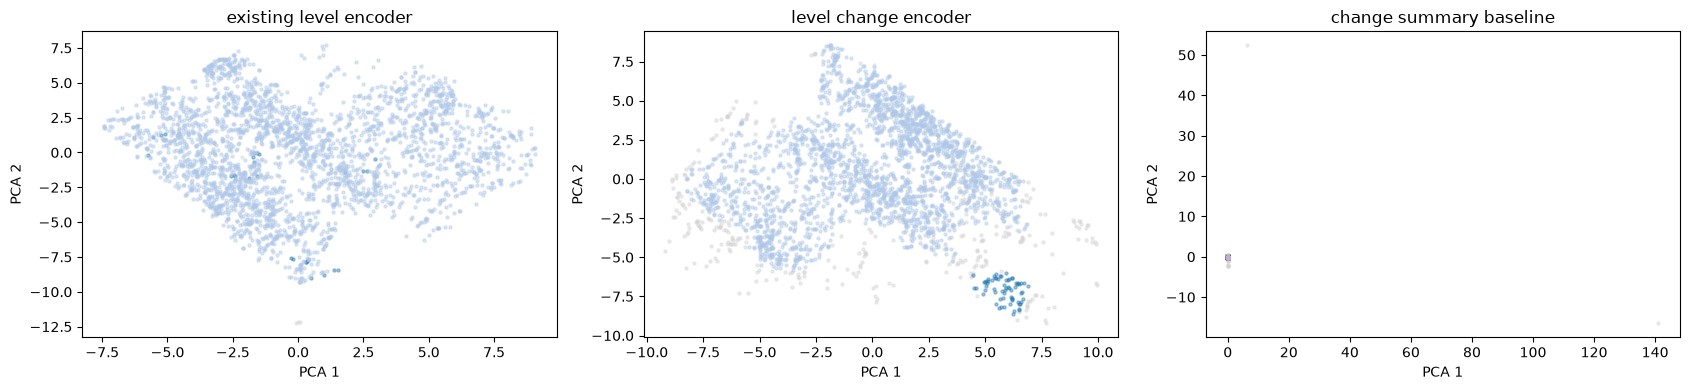

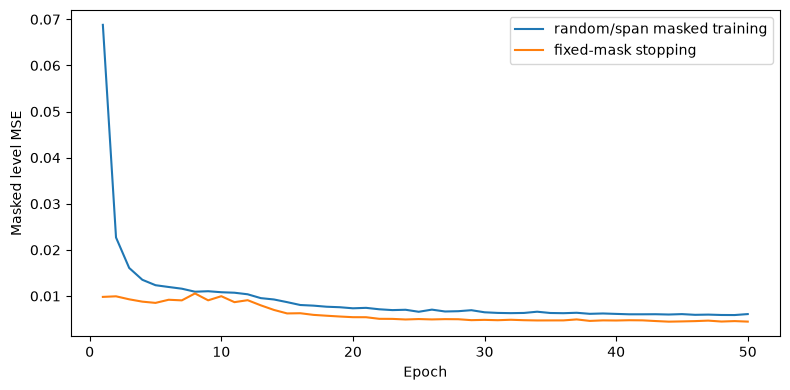

NOTEBOOK 05B COMPLETE — representation ablation saved.
Complete encoder training: True
Results: D:\SLIIT\Y4S1\RP\Research\J26-DS-342-\01_component_1_behavioral_drift_genai\results\single_model_q1q2_2021_v1\representation_ablation_v1_seed42
Share representation_comparison.csv, all_candidate_metrics.csv, temporal_comparison.csv and the saved notebook outputs.


In [11]:
fig,axes=plt.subplots(1,3,figsize=(17,4))
for ax,name in zip(axes,REPRESENTATIONS):
    ax.set_title(name.replace('_',' '))
    if name not in SELECTED:
        ax.text(.5,.5,'No eligible candidate',ha='center',transform=ax.transAxes);continue
    indices=np.sort(np.random.default_rng(SEED).choice(len(META['train']),min(3000,len(META['train'])),replace=False))
    coordinates=Z[name]['train'][indices];labels=ASSIGNMENTS[name]['train']['regime_label'].to_numpy()[indices]
    for label in sorted(set(labels)):
        select=labels==label
        ax.scatter(coordinates[select,0],coordinates[select,1],s=5,alpha=.4,color='lightgrey' if label<0 else plt.get_cmap('tab20')(int(label)%20))
    ax.set_xlabel('PCA 1');ax.set_ylabel('PCA 2')
fig.tight_layout();fig.savefig(OUT/'representation_training_clusters.png',dpi=180,bbox_inches='tight');plt.show()
fig,ax=plt.subplots(figsize=(8,4));h=pd.DataFrame(history)
ax.plot(h['epoch'],h['masked_training_mse'],label='random/span masked training')
ax.plot(h['epoch'],h['stopping_mse'],label='fixed-mask stopping');ax.set_xlabel('Epoch');ax.set_ylabel('Masked level MSE');ax.legend()
fig.tight_layout();fig.savefig(OUT/'new_encoder_training.png',dpi=180,bbox_inches='tight');plt.show()

for name,key in SELECTED.items():
    pipeline_path=MODELS/f'{name}_diagnostic_pipeline.joblib';pipeline=joblib.load(pipeline_path)
    points=Z[name]['development'][:32]
    a,b=predict(CLUSTERERS[(name,key)],points);c,d=predict(pipeline['clusterer'],points)
    np.testing.assert_array_equal(a,c);np.testing.assert_allclose(b,d)
for split in META:
    folder=EXPORT/'new_encoder'/split
    pd.testing.assert_frame_equal(pd.read_parquet(folder/'metadata.parquet'),META[split])
    with np.load(folder/'representations.npz') as a:
        assert a['embeddings'].shape==(len(META[split]),SETTINGS['width'])
        assert a['feature_errors'].shape==(len(META[split]),F)
        for key in a.files:assert np.isfinite(a[key]).all()
artifacts={}
for root in [MODELS,EXPORT]:
    for path in root.rglob('*'):
        if path.is_file():artifacts[str(path.relative_to(COMPONENT_ROOT))]=sha256(path)
record={'created_utc':datetime.now(timezone.utc).isoformat(),'run_id':RUN_ID,'ablation_id':ABLATION_ID,
    'analysis_complete':True,'training_complete':training_record['completed'],'settings':SETTINGS,
    'best_epoch':best_epoch,'best_stopping_mse':best_loss,'representations':summary.to_dict(orient='records'),
    'collapsed_representations':COLLAPSED,'artifact_sha256':artifacts,
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'torch':str(torch.__version__),'sklearn':sklearn.__version__,'hdbscan':version('hdbscan')},
    'failure_labels_used':False,'sealed_test_opened':False,
    'limitations':['one model/seed','exploratory sequential development','unlabeled training contamination possible',
        'conditional clustering stability only','overlapping windows','sampled DBCV','PCA cap differs in retained information',
        'new encoder has extra input parameters; not a strictly matched feature-only causal ablation',
        'daily changes alone may not create meaningful operating regimes','no final fault evaluation or drift adaptation']}
# Convert NaNs from optional summary diagnostics to JSON null.
record=json.loads(pd.Series({'record':record}).to_json())['record']
(OUT/'representation_ablation_complete.json').write_text(json.dumps(record,indent=2,allow_nan=False))
print('NOTEBOOK 05B COMPLETE — representation ablation saved.')
print('Complete encoder training:',training_record['completed'])
print('Results:',OUT)
print('Share representation_comparison.csv, all_candidate_metrics.csv, temporal_comparison.csv and the saved notebook outputs.')


## Interpret the outcome before continuing
- If the new encoder has stronger stability but little within-drive variation, it may represent stable drive types rather than temporal regimes.
- If the simple change baseline performs as well as the neural methods, report that finding; extra model complexity needs supporting evidence.
- If none passes, preserve the negative experiment. More hyperparameter trials on the same inspected development data are not independent validation.
- If a method is promising, review raw profiles and confidence in the physical feature meanings before building combined reconstruction/distance/transition scores.

Five-seed neural replication, more HDD models, contamination quarantine/retraining, frozen independent evaluation and safe drift adaptation remain outstanding. June remains unopened.

**Implementation references:**
- https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoder.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://hdbscan.readthedocs.io/en/latest/api.html

**Delivery validation:** checked notebook schema and Python syntax, masked-level/change non-leakage, gap-safe transition handling, deterministic inference, checkpoint reuse, metadata alignment, all-noise handling, and synthetic execution of training/export/clustering/comparison. Full research outputs must be produced from your saved local data; no real results are precomputed in this notebook.
